# ClusterCentroids
### <i>With a Regression Target </i>


### Imports

In [9]:
# pip install imblearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.under_sampling import RandomUnderSampler, ClusterCentroids
import warnings

warnings.filterwarnings("ignore")

# Loading the dataset
df = pd.read_csv("../../houses.csv")

# drop unneeded variables
df.drop(["id", "date", "lat", "long", 'zipcode'], axis=1, inplace=True)

df

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,1340,5650
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,1690,7639
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,2720,8062
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,1360,5000
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000.0,3,2.50,1530,1131,3.0,0,0,3,8,1530,0,2009,0,1530,1509
21609,400000.0,4,2.50,2310,5813,2.0,0,0,3,8,2310,0,2014,0,1830,7200
21610,402101.0,2,0.75,1020,1350,2.0,0,0,3,7,1020,0,2009,0,1020,2007
21611,400000.0,3,2.50,1600,2388,2.0,0,0,3,8,1600,0,2004,0,1410,1287


In [10]:
df.query("price <= price.quantile(0.99)", inplace=True)

<Axes: xlabel='target_binned', ylabel='Count'>

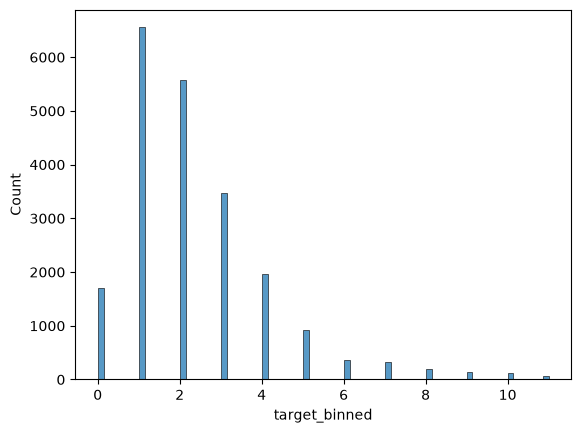

In [11]:
# Create 12 bins of price. 
target = "price"
df['target_binned'] = pd.cut(df[target], bins=12, labels=False)

# That looks like so.
sns.histplot(df, x="target_binned")

In [12]:
# This is really helpful to help you set the 'strategy' parameter in Undersampling.
# NOTE: This assumes your dataframe is called `df`

# Insert your column name here
column_name = "target_binned"

# Extract the unique values
column = df[column_name]
unique_values = column.unique()

# For each unique value, print the count.
for unique_value in unique_values:
    count = (column == unique_value).sum()
    print(unique_value,":", count)

# Now we know our upper limits when setting the strategy.

0 : 1704
2 : 5571
3 : 3476
7 : 328
1 : 6553
5 : 928
4 : 1957
8 : 190
6 : 368
9 : 132
11 : 73
10 : 116


---

# ClusterCentroids

This is typically used to preserve cluster relationships and tries to represent that structure with fewer points.

In [13]:
from imblearn.under_sampling import ClusterCentroids

# X, y split
X = df.drop('target_binned', axis=1)
y = df['target_binned']

# Set the strategy to tailor our needs. In this case
# Say we did some extensive research into this data
# and it's more realistic that all the diamonds have
# a normally distributed price. Let's make it look 
# that way instead.
strategy = {
    0 : 1704,
    1 : 4553,
    2 : 4571,
    3 : 3476,
    4 : 1957,
    5 : 928,
    6 : 368,
    7 : 328,
    8 : 190,
    9 : 132,
    10 : 116,
    11 : 73
}


# Create the ClusterCentroids sampler
sampler = ClusterCentroids(sampling_strategy=strategy, random_state=321)

# Use the sampler
X_resampled, y_resampled = sampler.fit_resample(X, y)

# Put the dataframe back together after sampling
df_resampled_cc = pd.DataFrame(
    X_resampled,
    columns=X.columns
)

# Keep the binned target
df_resampled_cc['target_binned'] = y_resampled


<Axes: xlabel='target_binned', ylabel='Count'>

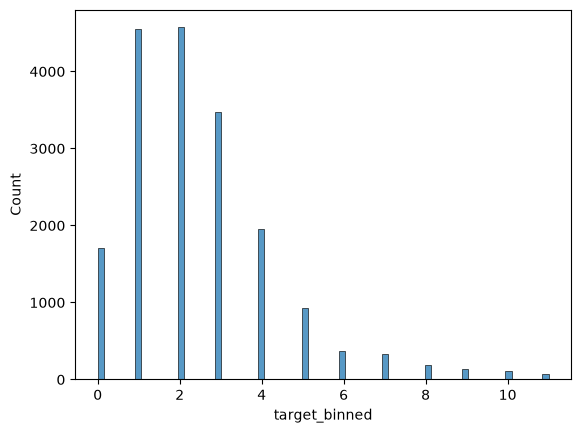

In [14]:
sns.histplot(df_resampled_cc, x="target_binned")

In [15]:
# switching to decimal notation for the variance checks
pd.set_option('display.float_format', lambda x: "%.2f" % x)

In [16]:
# Comparing the two statistically
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15,target_binned
count,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00
mean,518115.33,3.36,2.10,2050.49,14993.24,1.49,0.01,0.22,3.41,7.63,1766.21,284.28,1970.99,82.27,1971.61,12696.71,2.33
std,284587.46,0.92,0.75,861.41,40979.49,0.54,0.07,0.73,0.65,1.14,791.59,430.40,29.31,396.79,668.10,27203.76,1.83
min,75000.00,0.00,0.00,290.00,520.00,1.00,0.00,0.00,1.00,1.00,290.00,0.00,1900.00,0.00,399.00,651.00,0.00
25%,320000.00,3.00,1.50,1420.00,5026.00,1.00,0.00,0.00,3.00,7.00,1190.00,0.00,1951.75,0.00,1480.00,5100.00,1.00
50%,450000.00,3.00,2.25,1900.00,7575.50,1.50,0.00,0.00,3.00,7.00,1550.00,0.00,1975.00,0.00,1830.00,7600.00,2.00
75%,635000.00,4.00,2.50,2520.00,10548.50,2.00,0.00,0.00,4.00,8.00,2190.00,550.00,1997.00,0.00,2340.00,10021.25,3.00
max,1960000.00,33.00,7.50,7730.00,1651359.00,3.50,1.00,4.00,5.00,13.00,7420.00,3260.00,2015.00,2015.00,5790.00,871200.00,11.00


In [17]:
df_resampled_cc.describe()

# The same as RandomUnderSampler, naturally. Because we used
# the same strategy. 

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15,target_binned
count,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00
mean,544385.10,3.38,2.13,2125.24,16437.16,1.49,0.01,0.24,3.40,7.67,1820.54,304.69,1970.35,95.47,2024.66,13762.30,2.49
std,296929.62,0.95,0.75,886.58,44012.05,0.52,0.08,0.77,0.65,1.19,819.09,445.86,29.21,425.97,687.28,29180.18,1.91
min,75000.00,0.00,0.00,290.00,520.00,1.00,0.00,0.00,1.00,1.00,290.00,0.00,1900.00,0.00,399.00,651.00,0.00
25%,334500.00,3.00,1.75,1470.00,5144.00,1.00,0.00,0.00,3.00,7.00,1210.00,0.00,1951.00,0.00,1510.00,5195.00,1.00
50%,482500.00,3.00,2.25,2000.00,7838.00,1.50,0.00,0.00,3.00,7.00,1606.50,0.00,1973.00,0.00,1890.00,7790.00,2.00
75%,675000.00,4.00,2.50,2630.00,11458.00,2.00,0.00,0.00,4.00,8.00,2290.00,600.00,1995.00,0.00,2425.00,10570.00,3.00
max,1960000.00,33.00,7.50,7730.00,1651359.00,3.50,1.00,4.00,5.00,13.00,7420.00,3260.00,2015.00,2015.00,5790.00,871200.00,11.00
